In [1]:
import numpy as np
import matplotlib.pyplot as plt
import gebtaero_jax as gx

c, I11 = 1.8288, 8.64
cs = gx.CrossSection.from_isotropic(9.77e6, 0.0, 0.99e6).with_mass(35.71, 1e-4 * I11, I11, 0.0, nu=0.18288)
geom = dict(span=6.096, chord=c, a=-0.34, n_elements=10)
air = gx.FlightCondition(rho=1.225)

## Flutter speed for every aerodynamic model

In [2]:
ref = {gx.Aero.QUASI_STEADY: 35.26, gx.Aero.QUASI_STEADY_ADDED_MASS: 64.34, gx.Aero.PETERS: 136.5, gx.Aero.WAGNER: None}
for aero, r in ref.items():
    p = gx.flutter_speed(gx.straight_wing(cs, aero=aero, **geom), air, 10.0, 200.0, n_grid=20)
    print(f"{aero.name:<26s} V_f = {p.velocity:8.3f} m/s  f = {p.frequency_hz:6.3f} Hz   GEBTAero ref: {r}")
pd = gx.divergence_speed(gx.straight_wing(cs, aero=gx.Aero.PETERS, **geom), air, 5.0, 300.0)
print(pd, " (GEBTAero: 253 m/s)")

QUASI_STEADY               V_f =   35.164 m/s  f = 14.985 Hz   GEBTAero ref: 35.26


QUASI_STEADY_ADDED_MASS    V_f =   64.332 m/s  f = 14.022 Hz   GEBTAero ref: 64.34


PETERS                     V_f =  136.507 m/s  f = 11.191 Hz   GEBTAero ref: 136.5


WAGNER                     V_f =  137.723 m/s  f = 11.079 Hz   GEBTAero ref: None


CriticalPoint(divergence: V=253.1819 m/s, f=0.0000 Hz)  (GEBTAero: 253 m/s)


## V-g diagram (Peters)

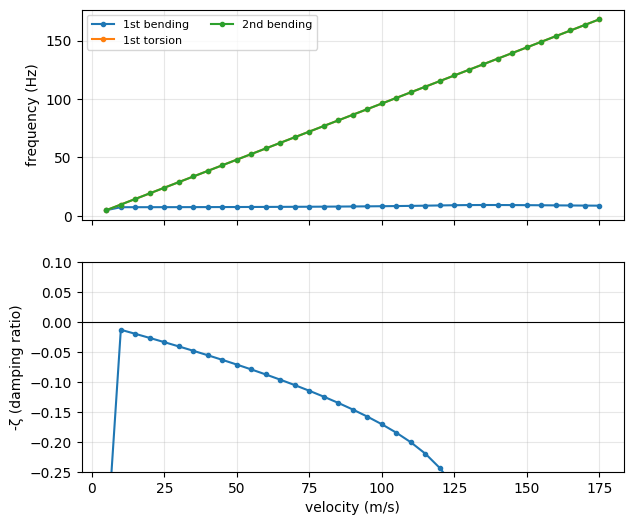

In [3]:
model = gx.straight_wing(cs, aero=gx.Aero.PETERS, **geom)
sweep = gx.mode_sweep(model, air, np.linspace(5, 175, 35), n_modes=3)
gx.plotting.plot_vg(sweep, labels=["1st bending", "1st torsion", "2nd bending"], ylim_damping=(-0.25, 0.1));

## Geometric invariance (GEBTAero tests 4–6)
A swept wing flown with an equal side-slip, a wing with dihedral, or a twisted wing flown at an angle of attack
that cancels the twist must all reproduce the straight-wing flutter speed (gravity on for the first two).

In [4]:
deg = np.pi / 180
cases = {
    "sweep 15° + sideslip 15°": (dict(sweep=15 * deg), dict(beta=15 * deg, gravity=9.81)),
    "dihedral 15°": (dict(dihedral=15 * deg), dict(gravity=9.81)),
    "twist 45° + AoA -45°": (dict(twist=np.pi / 4), dict(alpha=-np.pi / 4)),
}
for name, (g, f) in cases.items():
    m = gx.straight_wing(cs, aero=gx.Aero.PETERS, **geom, **g)
    print(f"{name:<26s}", gx.flutter_speed(m, gx.FlightCondition(rho=1.225, **f), 100, 160, n_grid=7))

sweep 15° + sideslip 15°   CriticalPoint(flutter: V=136.5068 m/s, f=11.1914 Hz)


dihedral 15°               CriticalPoint(flutter: V=136.5133 m/s, f=11.1908 Hz)


twist 45° + AoA -45°       CriticalPoint(flutter: V=136.5067 m/s, f=11.1914 Hz)


## Aeroelasticity.jl set-up
Same inputs as `docs/src/literate/goland-stability.jl` (note it uses `a = x_ref − 0.5 = −0.17`, i_22 = 0.1 i_11,
i_33 = 0.9 i_11, a reduced lift slope and Prandtl–Glauert compressibility). Their velocity grid is
`vcat(1, 5:5:200)`, hence the reported 140 m/s is the first unstable grid point.

In [5]:
cs_aj = gx.CrossSection.from_isotropic(9.77e6, 0, 0.99e6).with_mass(35.71, 0.1 * I11, 0.9 * I11, 0.0, nu=0.1 * c)
for aero in (gx.Aero.PETERS, gx.Aero.WAGNER):
    m = gx.straight_wing(cs_aj, 6.096, c, 0.33 - 0.5, 8, aero=aero, a0=0.85 * 2 * np.pi)
    p = gx.flutter_speed(m, gx.FlightCondition(rho=1.02, speed_of_sound=343.0), 100, 200, n_grid=11)
    print(f"{aero.name:<8s} V_f = {p.velocity:.2f} m/s, ω_f = {2*np.pi*p.frequency_hz:.2f} rad/s   (Aeroelasticity.jl: 140 m/s, 69.0 rad/s)")

PETERS   V_f = 135.08 m/s, ω_f = 69.01 rad/s   (Aeroelasticity.jl: 140 m/s, 69.0 rad/s)


WAGNER   V_f = 136.64 m/s, ω_f = 68.11 rad/s   (Aeroelasticity.jl: 140 m/s, 69.0 rad/s)


## Legacy GEBTAero input file
`goland.dat` is the Fortran input of the original repository (with gravity on).

In [6]:
case = gx.read_dat("../examples/data/goland.dat")
m = case.wing.discretize(case.aero_flag)
print("aero flag:", case.aero_flag, " gravity:", case.flight.gravity)
print(gx.modal_analysis(m, case.flight).table(4))
print(gx.flutter_speed(m, case.flight, 100, 160, n_grid=7))

aero flag: 3  gravity: 9.81


[[-1.42213677  8.19674056]
 [-0.90610126 13.15723997]
 [-1.82084838 37.98707682]
 [-0.49662242 55.59810942]]


CriticalPoint(flutter: V=136.5122 m/s, f=11.1917 Hz)


## Flutter mode shape at the flutter point

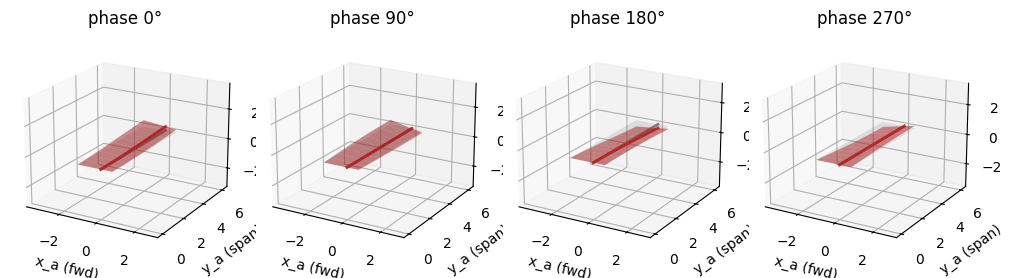

In [7]:
pf = gx.flutter_speed(model, air, 100, 160, n_grid=7)
res = gx.modal_analysis(model, air.replace(velocity=pf.velocity))
j = int(np.argmin(np.abs(res.eigvals - pf.eigval)))
phi = res.right[:, j] / np.abs(res.right[-3:, j]).max()
fig = plt.figure(figsize=(10, 4))
for i, ph in enumerate(np.linspace(0, 2 * np.pi, 4, endpoint=False)):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    x = 0.3 * np.real(phi * np.exp(1j * ph))
    gx.plotting.plot_wing_3d(model, None, ax=ax, color="grey", alpha=0.15)
    gx.plotting.plot_wing_3d(model, x, ax=ax, color="C3", alpha=0.5)
    gx.plotting.set_equal_3d(ax); ax.set_title(f"phase {np.degrees(ph):.0f}°"); ax.view_init(20, -60)
plt.tight_layout()